### EN3160 Assignment 2 on Fitting and Alignment

#### Index Number: 230724E
#### Name: Wijesekara WAGS

---

##### Github Link:  https://github.com/SathsaraGeeth/_vision_a02_.git

## 1. Blob Detection


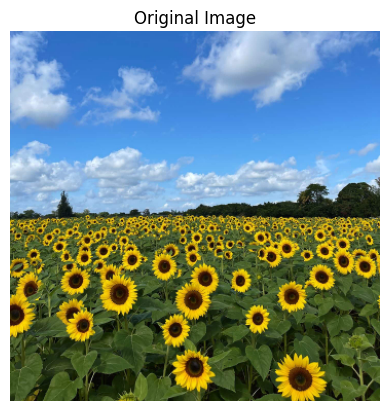

Blob 1: center=(282, 338), radius=10.14 pixels
Blob 2: center=(179, 327), radius=9.00 pixels
Blob 3: center=(106, 255), radius=7.85 pixels
Blob 4: center=(178, 261), radius=7.85 pixels
Blob 5: center=(189, 240), radius=6.71 pixels
Blob 6: center=(161, 290), radius=6.71 pixels
Blob 7: center=(63, 243), radius=6.71 pixels
Blob 8: center=(274, 258), radius=6.71 pixels
Blob 9: center=(303, 239), radius=5.56 pixels
Blob 10: center=(241, 279), radius=5.56 pixels


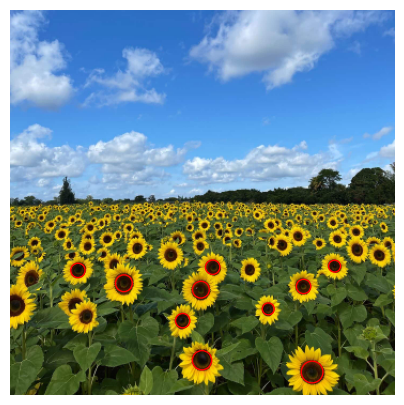

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

im = cv.imread("the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)

plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

# ker_sz shall be an odd positive integer
def NormalizedLapOfGauss2D(sigma, ker_sz):
    x = np.arange(-(ker_sz // 2), ker_sz // 2 + 1)
    y = np.arange(-(ker_sz // 2), ker_sz // 2 + 1)
    X, Y = np.meshgrid(x, y)
    r2 = X**2 + Y**2
    kernel = (r2 - 2 * sigma**2) / (2 * np.pi * sigma**6)
    kernel *= np.exp(-r2 / (2 * sigma**2))
    kernel *= sigma**2
    kernel -= kernel.mean()

    return kernel

def BlobDetector(image, num_blobs=25, threshold_rel=0.03, sigma_min=1.5, sigma_max=25, num_scales=30):
                 
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float64)

    sigmas = np.linspace(sigma_min, sigma_max, num_scales)
    responses = []

    # Convolve image with scale-normalized Laplacian at several scales
    for sigma in sigmas:
        ker_sz = 2 * int(np.ceil(3 * sigma)) + 1
        kernel = NormalizedLapOfGauss2D(sigma, ker_sz)
        response = cv.filter2D(gray, cv.CV_64F, kernel, borderType=cv.BORDER_REFLECT101)
        responses.append(response ** 2)

    # Find maxima of squared Laplacian response in scale-space
    scale_space = np.stack(responses, axis=0)
    local_max = maximum_filter(scale_space, size=(3, 3, 3))
    threshold = threshold_rel * scale_space.max()
    maxima = (scale_space == local_max) & (scale_space > threshold)

    maxima[0] = False
    maxima[-1] = False

    scale_idx, ys, xs = np.where(maxima)

    height, width = gray.shape
    candidates = []
    for s, y, x in zip(scale_idx, ys, xs):
        radius = np.sqrt(2) * sigmas[s]

        if x - radius < 0 or x + radius >= width:
            continue
        if y - radius < 0 or y + radius >= height:
            continue

        score = float(scale_space[s, y, x])
        candidates.append((int(x), int(y), float(radius), score))

    candidates.sort(key=lambda blob: blob[3], reverse=True)
    detected = []
    for x, y, radius, score in candidates:
        overlaps = any((x - px)**2 + (y - py)**2 < max(radius, pr)**2 for px, py, pr in detected)
        if not overlaps:
            detected.append((x, y, radius))

    return detected[:num_blobs]

# Limit to 10 largest blobs out of strongest 25 detections
blobs = sorted(BlobDetector(im, num_blobs=25), key=lambda blob: blob[2], reverse=True)[:10]

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for index, (x, y, radius) in enumerate(blobs, start=1):
    ax.add_patch(plt.Circle((x, y), radius, color='red', fill=False))
    print(f"Blob {index}: center=({x}, {y}), radius={radius:.2f} pixels")


ax.axis("off")
plt.show()

The image was first converted to grayscale. It was then convolved with the scale-normalized Laplacian of Gaussian at 30 scales in the range $1.5 \leq \sigma \leq 25$. The blobs were found by looking for maxima of the squared Laplacian response in space and scale. Responses below 3% of the maximum response were ignored, together with detections touching the image boundary. Overlapping detections were removed, and the 10 largest circles from the 25 strongest detections were drawn. The radius of each blob was found using $r=\sqrt{2}\sigma$.

The detected circle parameters $(x,y,r)$ are printed by the code.